In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# loading dataset
df = pd.read_csv(r'/content/drive/My Drive/Colab Notebooks/Feature Engineering/titanic.csv')
print(df)

print("Dataset loaded successfully!")

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

**Data preprocessing and splitting**

In [4]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp',
        'Parch', 'Fare', 'Embarked']]

y = df['Survived']

numerical_features = ['Pclass', 'Age', 'SibSp',
                      'Parch', 'Fare']

categorical_features = ['Sex', 'Embarked']

numerical_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Preprocessing completed successfully!")

Training Samples: 712
Testing Samples: 179
Preprocessing completed successfully!


**Uncontrolled Decision Tree**

In [5]:
dt_uncontrolled = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

dt_uncontrolled.fit(X_train_processed, y_train)

train_pred = dt_uncontrolled.predict(X_train_processed)
test_pred = dt_uncontrolled.predict(X_test_processed)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Uncontrolled Decision Tree")
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)
print("Tree Depth:", dt_uncontrolled.get_depth())
print("Number of Leaves:", dt_uncontrolled.get_n_leaves())

Uncontrolled Decision Tree
Training Accuracy: 0.9831460674157303
Testing Accuracy: 0.8268156424581006
Tree Depth: 23
Number of Leaves: 152


**Visualize how the Decision Tree splits data**

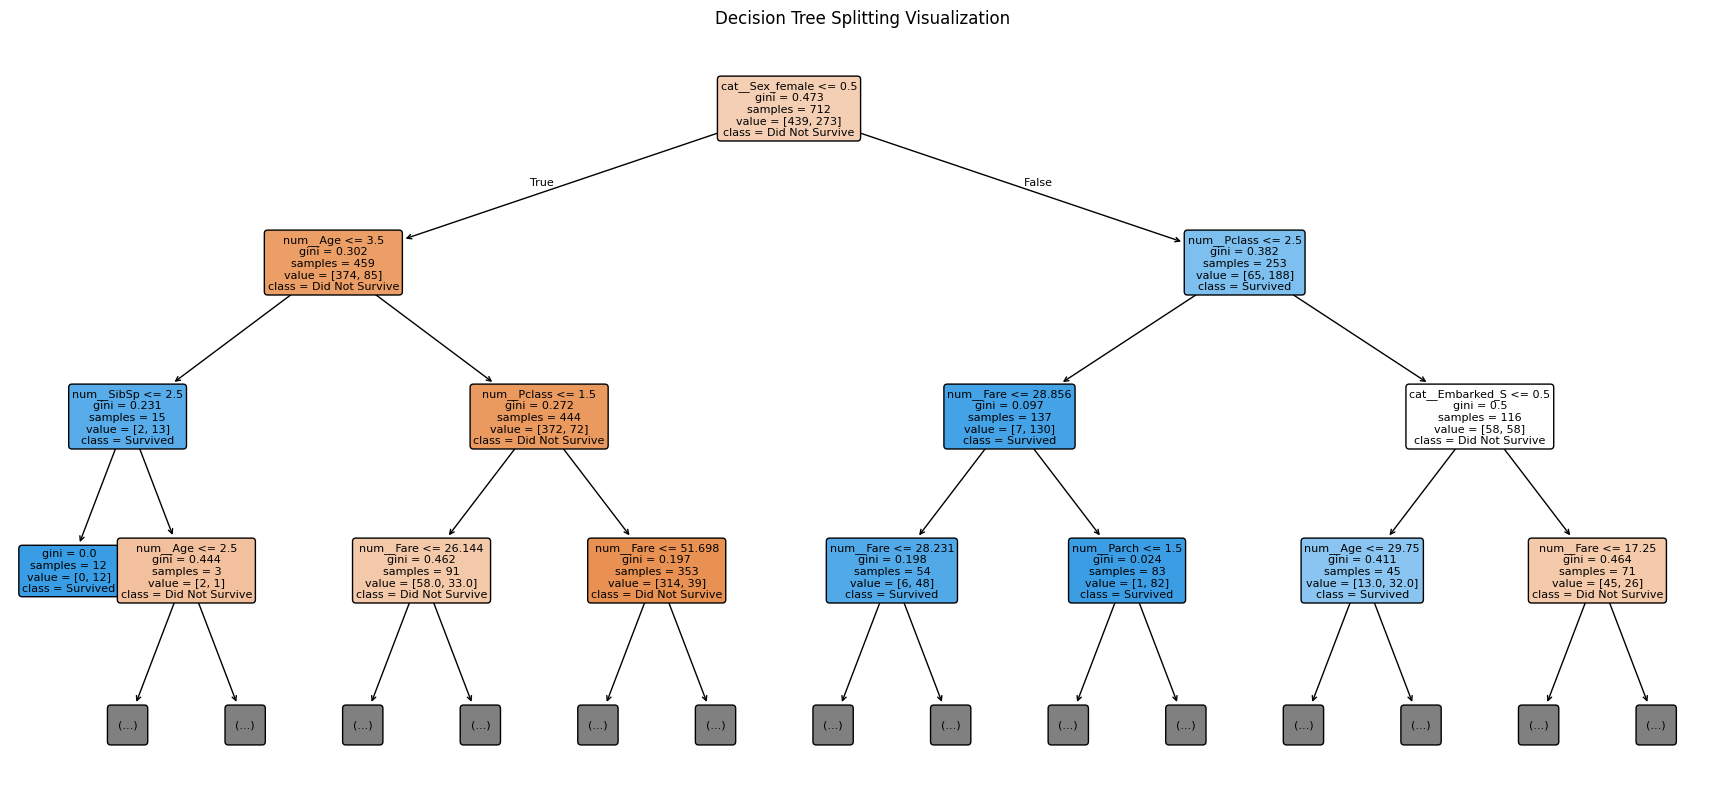

In [6]:
plt.figure(figsize=(22, 10))

plot_tree(
    dt_uncontrolled,
    feature_names=feature_names,
    class_names=['Did Not Survive', 'Survived'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Splitting Visualization")
plt.show()

**Controlled Decision Tree**

In [7]:
dt_controlled = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_controlled.fit(X_train_processed, y_train)

controlled_train_pred = dt_controlled.predict(X_train_processed)
controlled_test_pred = dt_controlled.predict(X_test_processed)

controlled_train_accuracy = accuracy_score(
    y_train, controlled_train_pred
)

controlled_test_accuracy = accuracy_score(
    y_test, controlled_test_pred
)

print("Controlled Decision Tree")
print("Training Accuracy:", controlled_train_accuracy)
print("Testing Accuracy:", controlled_test_accuracy)
print("Tree Depth:", dt_controlled.get_depth())
print("Number of Leaves:", dt_controlled.get_n_leaves())

Controlled Decision Tree
Training Accuracy: 0.8356741573033708
Testing Accuracy: 0.776536312849162
Tree Depth: 4
Number of Leaves: 14


**Visualize the controlled Decision Tree**

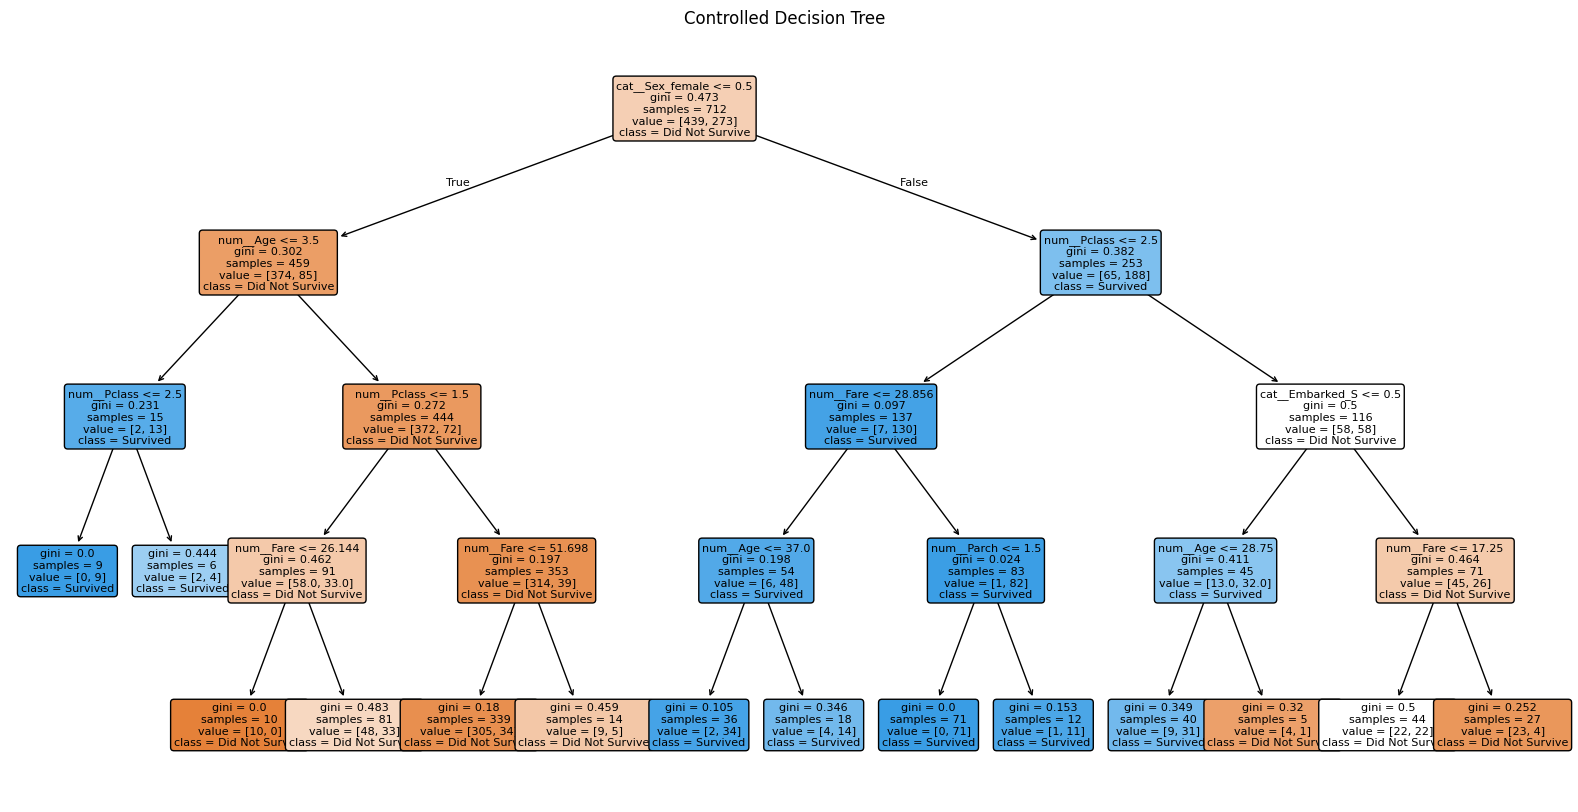

In [9]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_controlled,
    feature_names=feature_names,
    class_names=['Did Not Survive', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Controlled Decision Tree")
plt.show()

**Compare both Decision Trees**

In [8]:
comparison = pd.DataFrame({
    'Model': ['Uncontrolled Tree', 'Controlled Tree'],
    'Training Accuracy': [
        train_accuracy,
        controlled_train_accuracy
    ],
    'Testing Accuracy': [
        test_accuracy,
        controlled_test_accuracy
    ]
})

print("Decision Tree Performance Comparison")
display(comparison)

Decision Tree Performance Comparison


,Model,Training Accuracy,Testing Accuracy
0,Uncontrolled Tree,0.983146,0.826816
1,Controlled Tree,0.835674,0.776536


**Visualize the effect of tree depth on overfitting**

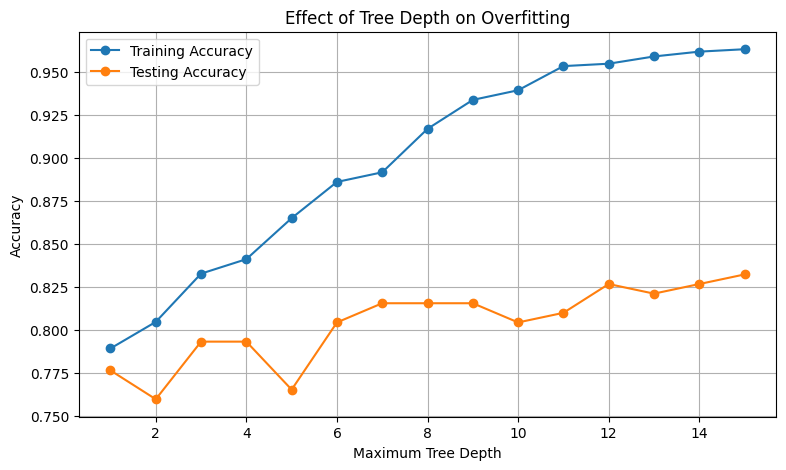

In [10]:
depths = range(1, 16)

train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    train_scores.append(
        model.score(X_train_processed, y_train)
    )

    test_scores.append(
        model.score(X_test_processed, y_test)
    )

plt.figure(figsize=(9, 5))

plt.plot(depths, train_scores, marker='o',
         label='Training Accuracy')

plt.plot(depths, test_scores, marker='o',
         label='Testing Accuracy')

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Overfitting")

plt.legend()
plt.grid()
plt.show()

**Evaluate the controlled model**

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179



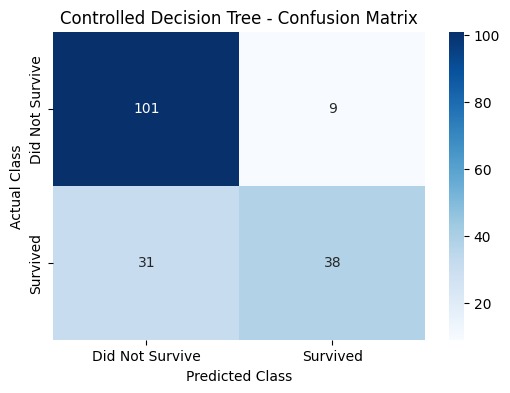

In [11]:
print("Classification Report:")

print(classification_report(
    y_test,
    controlled_test_pred,
    target_names=['Did Not Survive', 'Survived']
))

cm = confusion_matrix(y_test, controlled_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Did Not Survive', 'Survived'],
    yticklabels=['Did Not Survive', 'Survived']
)

plt.title("Controlled Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

**Feature importance**

Top Important Features:


,0
cat__Sex_female,0.593517
num__Pclass,0.206451
num__Age,0.105275
num__Fare,0.055615
cat__Embarked_S,0.038309
num__Parch,0.000833
num__SibSp,0.000000
cat__Sex_male,0.000000
cat__Embarked_C,0.000000
cat__Embarked_Q,0.000000


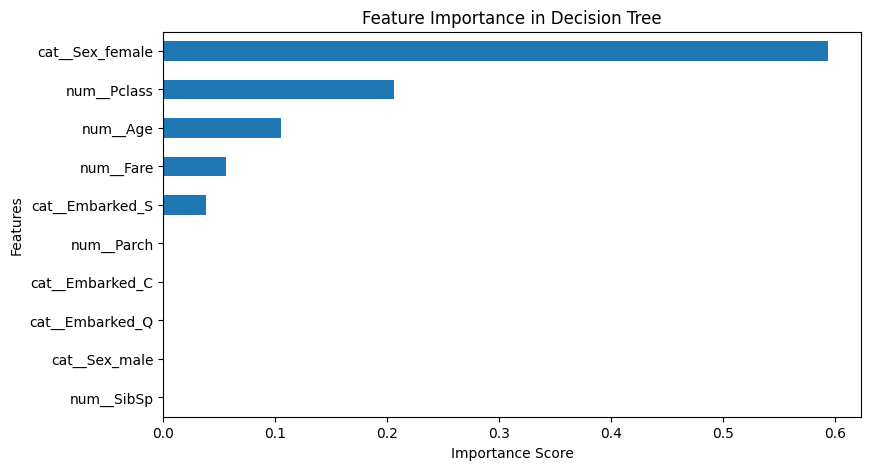

In [12]:
importance = pd.Series(
    dt_controlled.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Top Important Features:")
display(importance.head(10))

plt.figure(figsize=(9, 5))

importance.head(10).sort_values().plot(kind='barh')

plt.title("Feature Importance in Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

**Final observation**

In [14]:
print("FINAL OBSERVATION")

print("Uncontrolled Tree Training Accuracy:",
      round(train_accuracy, 4))

print("Uncontrolled Tree Testing Accuracy:",
      round(test_accuracy, 4))

print("Controlled Tree Training Accuracy:",
      round(controlled_train_accuracy, 4))

print("Controlled Tree Testing Accuracy:",
      round(controlled_test_accuracy, 4))

print("\nOverfitting can be controlled using:")
print("1. max_depth")
print("2. min_samples_split")
print("3. min_samples_leaf")
print("4. Pruning using ccp_alpha")

FINAL OBSERVATION
Uncontrolled Tree Training Accuracy: 0.9831
Uncontrolled Tree Testing Accuracy: 0.8268
Controlled Tree Training Accuracy: 0.8357
Controlled Tree Testing Accuracy: 0.7765

Overfitting can be controlled using:
1. max_depth
2. min_samples_split
3. min_samples_leaf
4. Pruning using ccp_alpha
